**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**03 | Statistical Feature Engineering for Wearable Signals**

![Stage 03 scientific workflow](../../images/03_workflow.svg)

**Objective:** Extract interpretable statistical features from HARTH's two-second acceleration windows and examine their distributions across annotated activities.

**Dataset:** The pinned HARTH v2.0 recording `S023.csv`, using six lower-back and thigh acceleration channels at 50 Hz.

**Notebook Scope:** Reuse the label-pure windowing protocol, calculate five statistics per channel, inspect the resulting 30-feature matrix and examine activity-level RMS distributions. No fitted scaling, feature selection or classifier training is performed.

**01. Imports and Environment**

In [1]:
# ======================== 01. Imports and Environment ========================

# ----------- 1. Import standard-library tools for portable paths. ------------
import sys
from pathlib import Path

# ----------- 2. Load plotting tools for original sensor features. ------------
import matplotlib.pyplot as plt

# -------------- 3. Import NumPy and pandas for feature tables. ---------------
import numpy as np
import pandas as pd

# ------------------ 4. Import the notebook display utility. ------------------
from IPython.display import display

# ------------- 5. Resolve repository root before local imports. --------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root.parent == root:
        raise RuntimeError("Open this notebook inside the repository.")
    root = root.parent

# ------------ 6. Register shared and HARTH-specific module paths. ------------
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ------------- 7. Import validated HARTH and feature utilities. --------------
from core.data_inspection import inspect_data
from core.signal_preprocessing import create_signal_windows
from core.feature_engineering import extract_signal_features, AVAILABLE_FEATURES
from harth_data import ACTIVITY_NAMES, ensure_harth_sample, load_harth_subject

# -------------- 8. Apply the approved academic plotting style. ---------------
from core.plot_style import plot_style
plot_style()

# -------------- 9. Confirm the repository and feature methods. ---------------
print("Repository:", root)
print("Available methods:", AVAILABLE_FEATURES)

Repository: D:\human-movement-intelligence
Available methods: ('mean', 'std', 'rms', 'peak_to_peak', 'waveform_length')


**02. Load Original HARTH Signals**

Load the `S023.csv` recording and verify the six accelerometer channels in the source unit **g**.

In [2]:
# ====================== 02. Load Original HARTH Signals ======================

# --------------- 1. Locate the ignored original source cache. ----------------
data_dir = root / "data" / "raw" / "harth_v2"

# ------------- 2. Retrieve or reuse the original S023 recording. -------------
csv_path = ensure_harth_sample(data_dir, subject="S023")
data, channel_names = load_harth_subject(csv_path)

# ---------------- 3. Inspect the six channels and raw table. -----------------
inspect_data(data, name="HARTH: continuous sensor data")
print("Channels:", channel_names)

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S023.csv
HARTH subject S023: 137,646 rows, 6 sensors

===== HARTH: continuous sensor data =====
Rows: 137646 | Columns: 8
Missing values: 0
Columns: timestamp, back_x, back_y, back_z, thigh_x, thigh_y, thigh_z, label
              timestamp    back_x    back_y    back_z   thigh_x   thigh_y   thigh_z  label
2019-01-12 00:00:00.000 -1.108887  0.057861 -0.076904 -1.396973 -0.327148 -0.141846      6
2019-01-12 00:00:00.020 -1.054932  0.073486 -0.113770 -1.363281 -0.386475 -0.321533      6
2019-01-12 00:00:00.040 -0.911377 -0.007568 -0.160156 -1.080078 -0.096680 -0.354492      6
2019-01-12 00:00:00.060 -0.865234 -0.062500 -0.176025 -1.012939  0.163574 -0.229736      6
2019-01-12 00:00:00.080 -0.992920 -0.026123 -0.178467 -0.989014  0.199951 -0.088379      6
Channels: ['back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z']


**03. Recreate the Validated Windowing Protocol**

Use 100-sample windows with a 50-sample stride at 50 Hz. As in Notebook 02, reject windows crossing activity-label changes or timestamp discontinuities.

In [3]:
# ====================== 03. Recreate Label-Pure Windows ======================

# ----------- 1. Preserve the two-second and 50%-overlap protocol. ------------
SAMPLING_RATE = 50
WINDOW_SIZE = 100
STEP_SIZE = 50

# --------- 2. Segment continuous intervals with one activity label. ----------
X_windows, y_windows, window_info = create_signal_windows(
    signals=data[channel_names].to_numpy(),
    labels=data["label"].to_numpy(),
    window_size=WINDOW_SIZE,
    step_size=STEP_SIZE,
    timestamps=data["timestamp"],
    sampling_rate=SAMPLING_RATE,
    min_label_purity=1.0,
    subject_id=csv_path.stem,
)

# ---------------- 3. Report tensor shape and source indices. -----------------
print("Window tensor:", X_windows.shape)
print("Aligned labels:", y_windows.shape)
display(window_info.head())

Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Window tensor: (2567, 6, 100)
Aligned labels: (2567,)


,subject_id,start_index,end_index_exclusive,label,label_purity
0,S023,0,100,6,1.0
1,S023,50,150,6,1.0
2,S023,100,200,6,1.0
3,S023,150,250,6,1.0
4,S023,200,300,6,1.0


**04. Extract Statistical Features**

Calculate the mean, standard deviation, root mean square (RMS), peak-to-peak range and mean absolute difference between adjacent samples (normalised waveform length) for each of six channels. Each retained window produces 30 features without fitted scaling or supervised feature selection.

In [4]:
# ================== 04. Extract Thirty Statistical Features ==================

# --------- 1. Extract five statistics from each of six sensor axes. ----------
feature_table = extract_signal_features(
    X_windows,
    channel_names=channel_names,
    methods=["mean", "std", "rms", "peak_to_peak", "waveform_length"],
)

# -------------- 2. Inspect feature dimensions and column names. --------------
feature_report = inspect_data(feature_table, name="HARTH statistical feature matrix")

# ------------ 3. Display a sample of the extracted feature rows. -------------
print("First feature columns:", feature_table.columns[:10].tolist())
display(feature_table.head())

Input windows: (2567, 6, 100)
Feature matrix: (2567, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length

===== HARTH statistical feature matrix =====
Rows: 2567 | Columns: 30
Missing values: 0
Columns: back_x__mean, back_x__std, back_x__rms, back_x__peak_to_peak, back_x__waveform_length, back_y__mean, back_y__std, back_y__rms, back_y__peak_to_peak, back_y__waveform_length, back_z__mean, back_z__std, back_z__rms, back_z__peak_to_peak, back_z__waveform_length, thigh_x__mean, thigh_x__std, thigh_x__rms, thigh_x__peak_to_peak, thigh_x__waveform_length, thigh_y__mean, thigh_y__std, thigh_y__rms, thigh_y__peak_to_peak, thigh_y__waveform_length, thigh_z__mean, thigh_z__std, thigh_z__rms, thigh_z__peak_to_peak, thigh_z__waveform_length
 back_x__mean  back_x__std  back_x__rms  back_x__peak_to_peak  back_x__waveform_length  back_y__mean  back_y__std  back_y__rms  back_y__peak_to_peak  back_y__waveform_length  back_z__mean  back_z__std  back_z__rms  back_z__peak_to_peak  back_z__wavefor

,back_x__mean,back_x__std,back_x__rms,back_x__peak_to_peak,back_x__waveform_length,back_y__mean,back_y__std,back_y__rms,back_y__peak_to_peak,back_y__waveform_length,...,thigh_y__mean,thigh_y__std,thigh_y__rms,thigh_y__peak_to_peak,thigh_y__waveform_length,thigh_z__mean,thigh_z__std,thigh_z__rms,thigh_z__peak_to_peak,thigh_z__waveform_length
0,-0.986616,0.022918,0.986882,0.243653,0.010584,-0.009849,0.017442,0.020030,0.135986,0.008131,...,-0.060723,0.062084,0.086843,0.586426,0.023413,0.043762,0.074973,0.086810,0.516846,0.022024
1,-0.985547,0.005812,0.985564,0.033936,0.004520,-0.022791,0.014661,0.027099,0.052734,0.005558,...,-0.049792,0.015131,0.052041,0.062744,0.007899,0.072261,0.021348,0.075348,0.095215,0.010846
2,-0.986951,0.012642,0.987032,0.109864,0.006081,-0.046245,0.035022,0.058010,0.175048,0.007011,...,-0.036003,0.014824,0.038936,0.092041,0.006991,0.074793,0.021476,0.077815,0.109863,0.006853
3,-0.984619,0.031933,0.985137,0.177246,0.014318,-0.011624,0.114468,0.115057,0.443360,0.018283,...,-0.040164,0.065943,0.077211,0.365723,0.021169,0.066587,0.077204,0.101953,0.404053,0.022942
4,-0.980664,0.053464,0.982120,0.370362,0.023203,0.005269,0.143135,0.143232,0.565918,0.033534,...,-0.037969,0.124625,0.130280,0.628906,0.045156,-0.053779,0.151463,0.160728,0.598389,0.042086


**05. Compare RMS Features Across Activities**

Compare lower-back and thigh X-axis RMS values by annotated activity. These descriptive measurements are not classifier predictions.

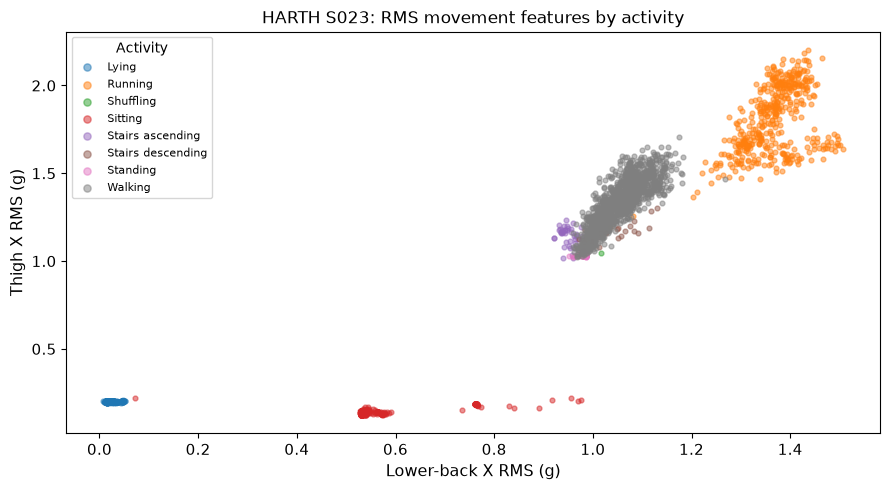

In [5]:
# =============== 05. Visualise Activity-Dependent RMS Features ===============

# ---------- 1. Select back and thigh RMS for descriptive plotting. -----------
plot_data = feature_table[["back_x__rms", "thigh_x__rms"]].copy()

# --------- 2. Attach actual labels; extraction itself is label-free. ---------
plot_data["activity"] = [ACTIVITY_NAMES[int(label)] for label in y_windows]

# ------------ 3. Plot RMS features coloured by observed activity. ------------
fig, ax = plt.subplots(figsize=(9, 5))
for activity, subset in plot_data.groupby("activity", sort=True):
    ax.scatter(
        subset["back_x__rms"],
        subset["thigh_x__rms"],
        s=12, alpha=0.5, label=activity,
    )
ax.set(
    title="HARTH S023: RMS movement features by activity",
    xlabel="Lower-back X RMS (g)",
    ylabel="Thigh X RMS (g)",
)
ax.legend(title="Activity", fontsize=8, markerscale=1.5)
fig.tight_layout()
plt.show()

**06. Inspect Feature Distributions and Class Support**

Examine retained window counts and RMS variability within each activity. Differences observed in one participant cannot establish performance on unseen participants.

,retained_windows,mean_back_x_rms,mean_thigh_x_rms
activity,,,
Walking,1352,1.051158,1.323975
Running,441,1.365743,1.806327
Lying,328,0.027020,0.200489
Sitting,257,0.580205,0.144822
Standing,114,0.980754,1.036934
Stairs ascending,42,0.950649,1.141175
Stairs descending,26,1.039741,1.167314
Shuffling,7,0.983734,1.049556


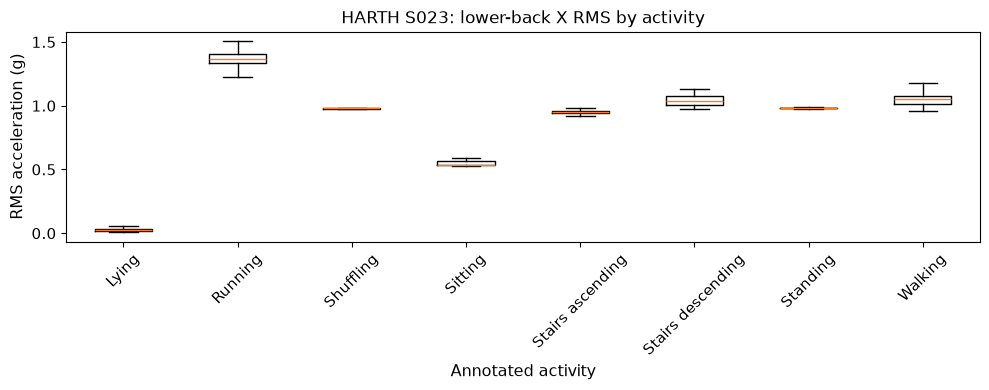

In [6]:
# =============== 06. Inspect Class Support and Feature Spread ================

# ------------ 1. Summarise class counts and mean RMS by activity. ------------
comparison = (
    plot_data.groupby("activity", sort=True)
    .agg(
        retained_windows=("back_x__rms", "size"),
        mean_back_x_rms=("back_x__rms", "mean"),
        mean_thigh_x_rms=("thigh_x__rms", "mean"),
    )
    .sort_values("retained_windows", ascending=False)
)

# ------------ 2. Display class support before interpreting plots. ------------
display(comparison)

# -------------- 3. Plot RMS variation across activity classes. ---------------
grouped = list(plot_data.groupby("activity", sort=True))
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(
    [group["back_x__rms"].to_numpy() for _, group in grouped],
    tick_labels=[activity for activity, _ in grouped],
    showfliers=False,
)
ax.set(
    title="HARTH S023: lower-back X RMS by activity",
    xlabel="Annotated activity",
    ylabel="RMS acceleration (g)",
)
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

**07. Statistical Feature Quality Gate**

Verify feature dimensions, finite values, unique feature names and alignment with source windows. Subject-independent evaluation requires a separate multi-participant design.


In [7]:
# =================== 07. Statistical Feature Quality Gate ====================

# ------------------- 1. Check window-to-feature alignment. -------------------
assert len(feature_table) == len(X_windows) == len(y_windows)

# ----------- 2. Verify 30 features, finite values and one subject. -----------
assert feature_table.shape[1] == len(channel_names) * len(AVAILABLE_FEATURES)
assert feature_table.columns.is_unique
assert np.isfinite(feature_table.to_numpy()).all()
assert window_info["subject_id"].nunique() == 1

# ------------- 3. Report results and single-subject limitations. -------------
print("Feature engineering: PASSED")
print("Samples:", len(feature_table), "| Features per sample:", feature_table.shape[1])
print("Independent subjects in this notebook: 1")
print("Feature standardisation fitted: NO")
print("Classifier trained: NO")
print("Subject-independent evaluation: NOT YET PERFORMED")

Feature engineering: PASSED
Samples: 2567 | Features per sample: 30
Independent subjects in this notebook: 1
Feature standardisation fitted: NO
Classifier trained: NO
Subject-independent evaluation: NOT YET PERFORMED
